# Cloud Workload Forecasting - Capacity Recommendation

Plan = forecast + headroom. The headroom is learned from the model's errors in rolling-origin
validation (training window only), then checked on the holdout.
Assumption: running short of capacity costs 5 times more than unused capacity.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from cwfc.capacity import compare_headrooms, headroom_from_errors
from cwfc.data import build_targets, load_readings, split_train_holdout
from cwfc.evaluation import backtest
from cwfc.pipeline import forecast_cpu, make_predictions

data_dir = Path("challenge_data")
if not data_dir.exists():
    data_dir = Path("../challenge_data")

readings = load_readings(data_dir)
targets = build_targets(readings)
train, holdout = split_train_holdout(targets)
predictions = make_predictions(targets)

# Errors of the chosen model in rolling-origin validation (training window only)
cpu_train = train["aggregate_cpu_utilization"].to_numpy()
validation = backtest(cpu_train, forecast_cpu, horizon=24, min_train=48, step=6)

actual = holdout["aggregate_cpu_utilization"].to_numpy()
forecast = predictions["aggregate_cpu_utilization"].to_numpy()

## 1. Headroom levels
Each level `qXX` is the XX-th percentile of past under-forecast errors.

In [6]:
table = compare_headrooms(validation["actual"], validation["forecast"], actual, forecast)
table.round(3)

,headroom,coverage,mean_shortfall,mean_waste,cost
q50,0.000,0.625,0.035,0.063,0.238
q80,0.202,0.958,0.004,0.234,0.256
q90,0.396,1.000,0.000,0.424,0.424
q95,0.454,1.000,0.000,0.482,0.482
q99,0.533,1.000,0.000,0.561,0.561


**What I see:**
- q50 has no headroom: the median validation error is below zero. Without headroom, the plan covers only 62.5% of holdout steps.
- q80 (+0.20 points) covers 23 of 24 holdout steps with 0.23 points of unused capacity on average.
- q90 and above cover every step but waste about twice as much.
- q50 has the lowest cost on this holdout, but only because the holdout is calm.
  I do not pick the headroom from holdout results: that would tune the policy on the test data.
- With a 5:1 cost ratio, the best coverage in theory is 5 / (5 + 1) = 83% (newsvendor rule), which points to q80.

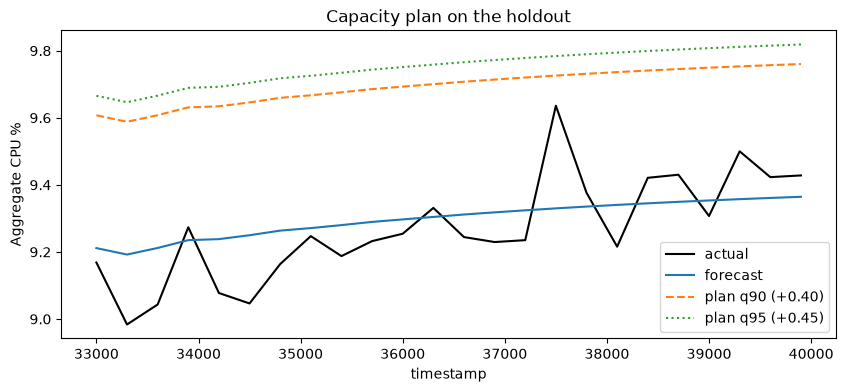

In [7]:
headroom_90 = headroom_from_errors(validation["actual"], validation["forecast"], 0.9)
headroom_95 = headroom_from_errors(validation["actual"], validation["forecast"], 0.95)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(holdout["timestamp"], actual, color="black", label="actual")
ax.plot(holdout["timestamp"], forecast, label="forecast")
ax.plot(holdout["timestamp"], forecast + headroom_90, linestyle="--", label=f"plan q90 (+{headroom_90:.2f})")
ax.plot(holdout["timestamp"], forecast + headroom_95, linestyle=":", label=f"plan q95 (+{headroom_95:.2f})")
ax.set_xlabel("timestamp")
ax.set_ylabel("Aggregate CPU %")
ax.set_title("Capacity plan on the holdout")
ax.legend()
plt.show()

**What I see:**
- The q80 plan sits about 0.2 points above the forecast, roughly 2% of the forecast load.
- The q90 and q95 plans stay well above the actual values. Their headroom was learned on a period
  that includes the bump, so it is conservative for a calm period like this holdout.
- The 9.64% spike at t=37,500 is the only step above the q80 plan (forecast 9.33 + 0.20 = 9.53).

## 2. Peak-risk trigger
The average CPU hides peaks, but the P95 of max_cpu across VMs shows them (see the exploration notebook).
Rule: if the current P95 of max_cpu is above the 90th percentile seen in training, use a bigger headroom.
The threshold comes from training data only. At run time, the rule only uses data up to the current timestamp.

Trigger level: 70.2%
Triggered in train: 11 of 110
Triggered in holdout: 0 of 24
Trigger timestamps: [16500, 16800, 17100, 17400, 17700, 18000, 18300, 18600, 18900, 19500, 20100]


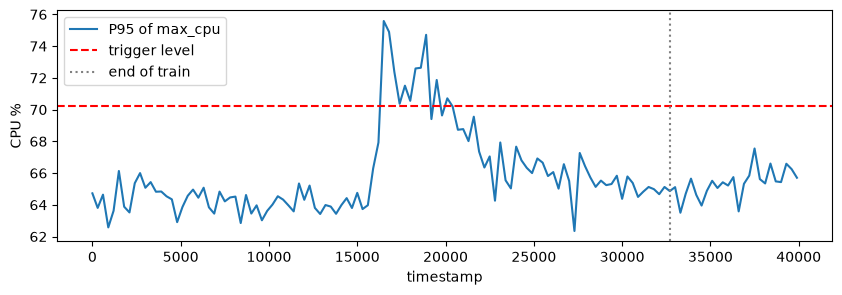

In [8]:
p95_max_cpu = readings.groupby("timestamp")["max_cpu"].quantile(0.95)
train_end = train["timestamp"].iloc[-1]
in_train = p95_max_cpu.index <= train_end

trigger_level = p95_max_cpu[in_train].quantile(0.9)
triggered = p95_max_cpu > trigger_level

print(f"Trigger level: {trigger_level:.1f}%")
print("Triggered in train:", int(triggered[in_train].sum()), "of", int(in_train.sum()))
print("Triggered in holdout:", int(triggered[~in_train].sum()), "of", int((~in_train).sum()))
print("Trigger timestamps:", list(triggered[triggered].index))

fig, ax = plt.subplots(figsize=(10, 3))
p95_max_cpu.plot(ax=ax, label="P95 of max_cpu")
ax.axhline(trigger_level, color="red", linestyle="--", label="trigger level")
ax.axvline(train_end, color="gray", linestyle=":", label="end of train")
ax.set_ylabel("CPU %")
ax.legend()
plt.show()

**What I see:**
- The trigger level is 70.2%. It fired on 11 training timestamps, all inside the bump (t=16,500 to 20,100), and never in the holdout.
- It fires at the start of the bump, not before. It is a fast detector, not a predictor.
- It is a much clearer signal than the average: the P95 of max_cpu rises by about 10 points while the average rises by 0.4.

## 3. Recommendation

1. **Normal mode:** plan aggregate CPU = forecast (`ridge_ar_lags3`) + 0.20 points (q80 of validation errors).
   On the holdout this covered 23 of 24 steps with about 2% extra capacity.
2. **Peak mode:** when the P95 of max_cpu across VMs goes above 70.2%, raise the headroom to q95 (+0.45 points)
   until it falls back below the level. In training, the trigger was active during the main part of the bump (t=16,500 to 20,100).
3. **VM count:** plan for the current count. The dataset has no churn, so this rule must be checked on data with VM creations and deletions.
4. **Keep it up to date:** recompute the headroom and the trigger level regularly on recent data,
   and raise the headroom if coverage over the last day drops below 80%.

**Trade-off:** less headroom saves money but risks slowdowns; more headroom is safer but pays for idle capacity.
The 5:1 cost ratio is an assumption: a team with stricter latency targets should use q90 instead.